# 사전과제 : AI 최적화 & 엔지니어링

# 0. AI 최적화의 정렬
- 지금까지의 흐름 회수 : 퍼셉트론 -> 역전파 -> CNN -> RNN -> 트랜스포머 -> LLM -> 생성모델
     - 문제 1) 이미 만들어진 AI를 어떻게 효율적으로 활용할까? : 전이학습 (학습 비용 줄이기 위해 사전학습 모델 재사용) , 경량화 (실행하는 데에 필요한 메모리와 연산량 줄이기 )
     - 문제 2) AI를 사람의 의도와 가치에 맞게 행동하려면? : AI 정렬 
     - 문제 3) AI에게 일을 맡기려면? : 프롬프트 엔지니어릴 (무엇을 요청할지 정하기), 에이전트 하네스 & 루프 (AI 쓸 도구랑 권한 지정,실행 환경에 따른 행동 결정 과정 설계)

# 1. 전이학습과 딥러닝 경량화
## 1. 전이학습이란?

### 1) 딥러닝 모델의 한계
- 예시 : 흉부 x-ray로 정상/폐렴 구분하는 AI 그렇지만 이미지는 100장 뿐
     - 1) 데이터의 부족 
     - 2) 데이터 부족으로 인한 과적합 발생
     - 3) 많은 시간과 비용 소모

## 2. 전이학습의 정의
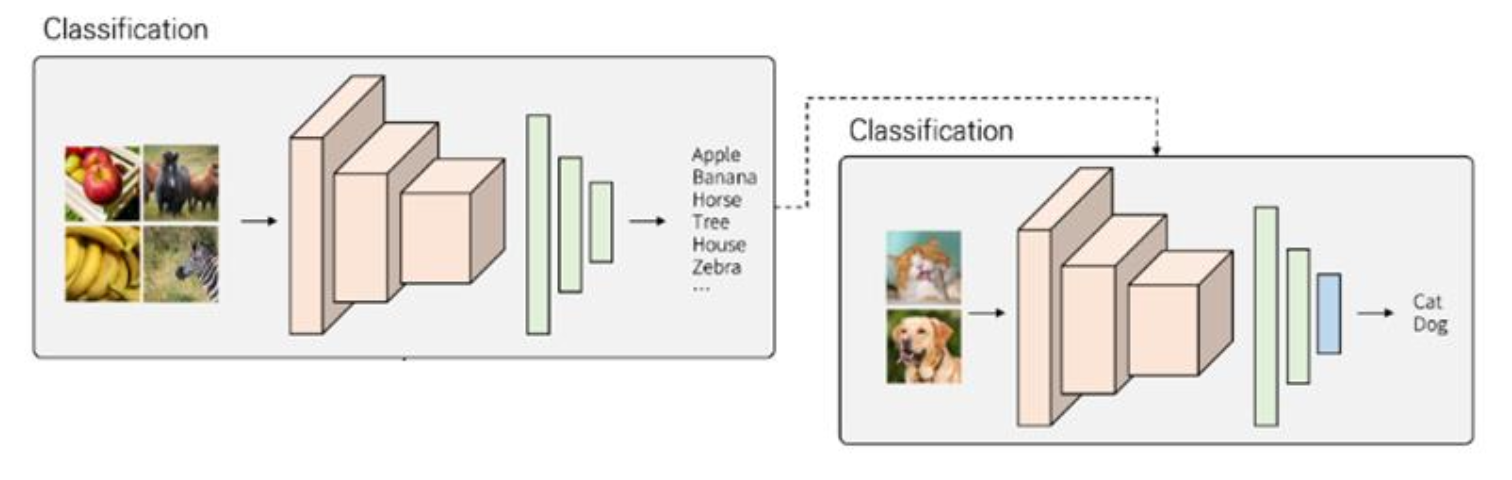
### 1) 전이학습이란?
- 정의 : 모델이 사전 학습을 통해 배운 능력을 활용해 새로운 작업 학습.
- 예시
     - 동물 사진으로 모델 사전 학습 : 특징 파악하는 법을 익히고, 모델의 가중치에 담김
     - 정상/폐렴 구분에 사용할 구분 가져오기 : 사전 학습된 특징 파악 능력을 그대로 활용. 분류층만 '정상과 폐럼'을 구분하는 새 분류층으로 교체
     - 정답이 있는 x-ray로 학습하기 : 정답 레이블이 존재하는 x-ray로 새 분류층 학습, *어떤 특징*이 구분하는데 중요한지 학습
     - fine tuning (선택) : 가중치도 x-ray에 맞게 조정이 가능
### 2) 용어 정리
- source : 기존에 학습한 문제 - 강아지 고양이 분류 문제 
- target : 새롭게 해결할 문제 - x-ray로 정상 질병 분류하는 문제
- domain : 사용한 데이터의 특성 - 일반 동물 사진 / x ray
- task : 수행하려는 작업 - 강아지 고양이 분류 / 정상과 질병 분류
- 정리 = source 와 target의 domain 이나 task 중 적어도 하나가 다를 때, source에서 배운 지식을 target에 활용하는 방법

## 3. 전이학습의 분류
### 1) domain 과 task 에 따른 분류
- 귀납적 전이학습 : 
     - 귀납 : 여러 사례들을 통해 처음 보는 사례에도 적용 가능한 규칙을 배우는 것
     - 기존에 학습한 모델 능력을 바탕으로 정답 레이블 존재하는 사진 여러 장 학습 -> 새로운 이미지 봐도 분류할 수 있도록.
     - source와 target의 domain은 같은데 task가 다른 경우.
          - 사진 속 고양이의 *존재 여부* 파악, *위치 분류* 가 각각 task이지만 domain은 같기에 모두 **고양이 사진**을 이용하면 됨.
          - target : 정답 레이블 필요 <-> source
    - domain, task 모두 다른 경우
          - 고양이 강아지 분류하기, 정상과 폐렴 분류하기 -> domain 다름 -> 각각 동물 사진, 흉부 x-ray 사진
          - target : 정답 레이블 필요 <-> source

### 2) 전이 대상에 따른 분류
- 전이 대상 : 새 작업을 배울 때 *기존 모델에서 가져오는 대상*
     - 인스턴스 기반의 전이 대상 : 기존 데이터 일부
     - 특성 기반의 전이 대상 : 데이터를 나타내는 특징 표현
     - **파라미터 기반**의 전이 대상 : 기존 모델의 학습된 *가중치 편향*
     - 관계 기반의 전이 대상 : 데이터나 개체 사이의 관계 패턴

## 4. 전이학습의 현재 패러다임 
### 1) 전통적 전이 학습
: 가중치와 단어 벡터 재사용
- 이미지 분야 : 정답 레이블이 있는 데규모 이미지 데이터로 CNN을 사전학습 (윤곽, 질감, 모양 등 특징 찾는 법 학습 -> 가중치에 능력 담김 -> 새 이미지 분류 시 이 가중치 사용 + 새로운 분류층으로 교체) 
- 언어 분야 : 미리 만든 단어 벡터의 재사용(대규모 말뭉치에서 단어를 나타내는 숫자 벡터 학습 -> 감정 분석이나 스팸 분류 모델의 입력으로 재사용 / 단, 문맥에 따른 의미 차이 안 담김)

### 2) 트랜스포머 이후의 전이학습
: 사전 학습 모델을 여러 작업에 활용
- 이미지 분야 : 사전학습한 모델을 여러 작업의 출발점으로 사용
      - 자기지도학습 : 이미지 일부 가리고 복원하는 과정에서 특징 파악
      - 이미지/텍스트 공동 학습 : 사진과 문장 함께 보여주며 이미지와 문장이 얼마나 잘 맞는지 판단

- 언어 분야 : 모델을 사전학습해서 문맥을 반영하는 표현 얻음
      - BERT 로 -> 분류층을 붙인다.
      - LLM으로 -> 기존의 문장 생성 구조 활용

### 3) FOUNDATION MODEL
- 정의 : 여러 작업에 활용할 수 있도록, 방대한 데이터로 사전학습된 모델, 하나의 모델에서 원하는 작업에 따라 *추가학습* (fine tuning) -> 여러 특화 모델 -> 시작점이 된 모델 = FOUNDATION MODEL
     - 사전학습 모델 : *어떤 데이터로* 미리 학습? <-> Foundation model : 여러 작업의 기반으로 *활용 가능성*에 초점

### 4) fine tuning 정의
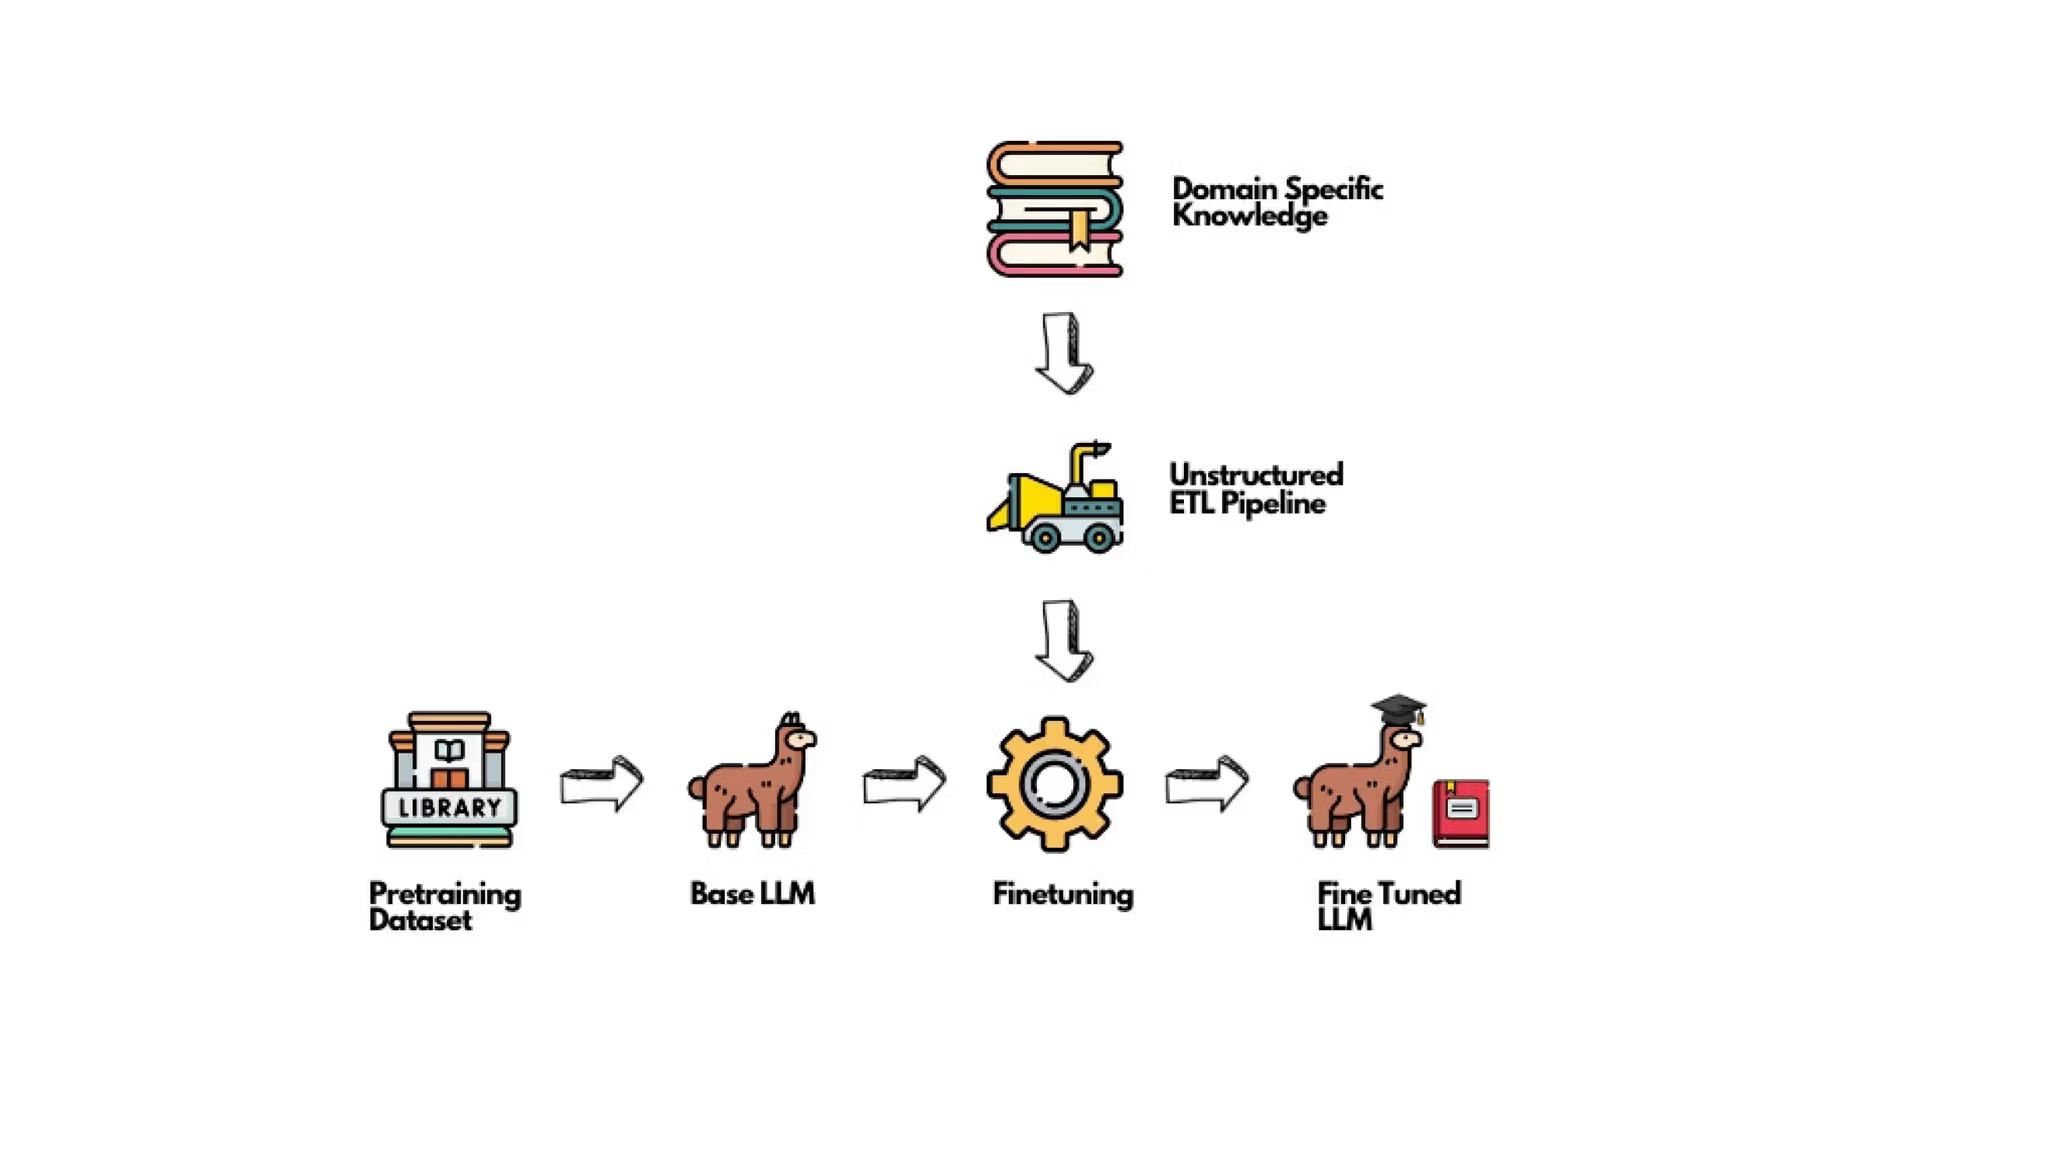
- 정의 : 사전 학습된 모델을 새 작업 데이터로 추가 학습 -> 기존 모델의 가중치 (일부 또는 전체) 수정
- 과정
     - 0. 기존 모델의 마지막 분류층을 새로운 분류층으로 교체 ( 강아지 고양이 -> x-ray)
     - 1. 특징 추출 :  기존 모델이 엑스레이 이미지에서 다양한 *시각적 특징 추출*
     - 2. 예측 : 새 분류층이 추출된 특징으로 정상/폐렴 예측
     - 3. 오차 계산 : 예측 결과와 실제 정답의 손실 계산
     - 4. 가중치 업데이트 : 역전파로 손실 줄이는 방향의 기울기 구하고, 가중치 업데이트 (*모델의 모든 가중치 업데이트 필요는 없다*)

### 5) fine tuning 방법
- **full fine tuning** : 모든 가중치 업데이트 / 모델 전체를 바꿀 수 있으나 학습 부담이 크다. 
     - 전체적으로 조정 가능하지만 메모리 사용량/연산 비용이 큼, 과적합 발생하거나 (데이터 부족시) catastrophic forgetting 문제 (기존 학습 지식 망각) 발생 가능
- **partial fine tuning** : 재사용할 층은 고정, 필요한 층만 업데이트
     - 앞쪽 선 (비교적 단순한 특징 : 선, 윤곽, 밝기 등) 고정 뒤쪽 층(앞쪽에서 추출한 특징-> 특정 작업에 필요한 복잡한 특징 학습) 학습
     - 학습 부담이 줄어듦, 그렇지만 어떤 층을 고정하고 어떤 층을 학습할지 결정해야한다는 단점
- **frozen backbone** : 새롭게 판단하는 부분만 학습
     - 학습 부담이 가장 작으나 새 작업에 필요한 특징을 잘 못 뽑아내는 한계.

- 선택 기준 : (적응 범위와 비용)-> frozen backbone < partial < full

## 5. fine - tuning의 한계를 넘어서

### 1) PEFT (parameter-efficient fine-tuning)
: 사전 학습 모델의 가중치 대부분/전반을 고정 -> 새 작업에 필요한 최소한의 파라미터만 학습
- 학습 하고 foundation model 한 번만 저장, 작업 별로 학습한 작은 파라미터 묶음만 저장(메모리부담낮음)

### 2) 구현 방법
- LoRA : 기존 모델에 더할 수정분을 *작은 두 행렬로 학습*, 기존 가중치를 고정시키고 출력에 더할 *보정값을 학습*하여 (정상/폐렴) 구분에 더 유용한 특징을 만들도록 할 수 있다.
     - Low rank : 수정 행렬을 작은 행렬 A,B의 곱으로 표현 가능
     - Adaptation: 보정으로 모델을 새 작업에 맞춘다 -> 기존 가중치는 고정하고 구분을 더 잘하기 위해 A,B를 학습
     - Adapter : 기존 모델 중간에 **작은 신경망**을 넣는다
     - Prompt tuning : 모델 **입력에 학습 가능한 숫자 벡터 붙임** -> 숫자 조정해서 모델이 분류에 용이한 특징 잘 뽑도록 유도

### 3) zero shot & few shot
- few shot : 몇 개의 예시를 프롬프트에 제공
- zero shot : 원하는 작업을 예시 없이 지시만 주는 방식

## 6. 전이학습의 한계
### 1) negative transfer
: 전이학습 적용 후가 새 작업에서의 성능이 더 낮은 경우

### 2) catastropic forgetting
: 새 데이터를 학습하면서 *기존 능력이 약해지는 경우* (새 성능은 좋아졌지만) <-> 1)

### 3) Bias Transfer
: 사전 학습에서 얻은 *편향이 새 작업에도 이어지는 경우* (사회적 편향, 사회적 문제)

### 4) transferability 측정의 어려움
- transferability : 사전 학습 모델이 배운 지식이 *새 작업에 얼마나 잘 활용될 수 있는가*
- 어떤 지식을 갖고 있는 모델이 새 작업에 잘 맞을지 미리 알기가 어렵다.

## 7. 전이학습 사례
1) CV- 의료영상 , X-ray 질환
2) NLP - 법률문서, 계약서 조항 분류

## 8. 딥러닝 모델 경량화
### 1) 4가지 방법

1. Pruning 
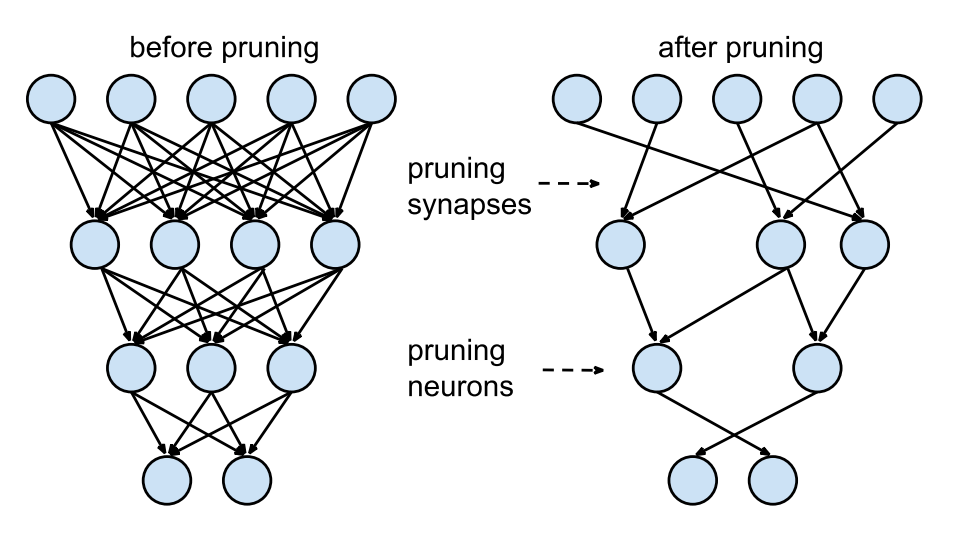 <br>
- 예측에 미치는 영향이 작은 부분 제거
2. 양자화
- 모델이 쓰는 숫자를 덜 정밀하게 표현 -> 저장공간 줄임
3. 지식 증류
- 큰 모델 = teacher 모델, 작은 student 모델이 정답과 teacher 모델의 출력 분포 함께 학습
4. 모델 구조 경량화
- 같은 작업을 더 적은 계산으로 수행하는 구조로 선택 (너무 단순하지는 않도록)


# 2. AI alignment
## 1. 정의

### 1) 기존 한계점
- 사실과 다른 문장, 사전 학습 데이터의 편향성 -> 사용자의 의도와 다르게 흘러갈 수 있다.

### 2) 정의
- 모델이 사람의 *의도와 목표를 이해*하고, 사람이 중요시 여기는 가치에 맞게 행동하도록 설계.
- *사람에게 바람직한게 무엇인지* 정렬하는 기준을 정하고, 그 기준에 맞게 답하도록 조정하는 것을 말한다.

### 3) 정렬 기준
- helpful : 사용자 의도 파악, 실질적으로 도움되는 답변 제공
- honest : 사실에 근거해서 답
- harmless : 답변이나 행동이 사람에게 해를 끼칠 가능성 줄임

### 4) 관점 2가지
- **outer alignment**: 목표 설정이 잘 되었는가?
     - 보상 해킹 : 보상 기준의 허점을 이용해서 점수만 높이는 것 -> 목표 설정이 잘못된 것이다.
- **inner alignment** : 모델이 실제로 무엇을 배웠는가?
     - 기만적 정렬 : 모델이 평가를 통가하기 위해서만 사람의 의도에 맞게 행동할 수도 있다.
     - 따라서 모델이 어떤 정보 활용하는지, 어떤 내부 계산을 거치는지 해석하는 연구가 중요

### 5) 정렬을 어렵게 만드는 요인
- 가치 정렬의 모호성 : 사람마다 다른 가치관 , 모두 동의할 수 없음
- 확장 가능한 감독 : 사람이 직접 확인할 수 있는 범위에는 한계가 존잰

## 2. RLHF
### 1) 정의
- 사전 학습으로 문맥에 맞게 이어질 말을 예측하는 능력을 익히고, 어떤 답변이 유용& 안전한지 피드백을 통해 학습이 가능하다 -> 사람들이 선호하는 답변에 높은 점수를 주는 RLHF 방식

### 2) 고전식 RLHF 파이프라인
- **SFT** : 답변 생성하도록 언어 모델을 학습시킨다. 사람이 작성한 모범 답변으로 학습시킨다.
- **reward model**: 사람의 선호를 점수로 변환, 사람이 선호한 답변에 더 높은 점수를 준다.
- **강화학습** : 학습된 보상을 최대화시킨다.

### 3) 부작용
- **Reward Hacking** : 좋은 답변보다는 *높은 보상 점수를 받도록*
- **Sycophancy** (아첨) : 모델이 *사용자 생각에 무조건적으로 동의*


# 3. 프롬프트 엔지니어링
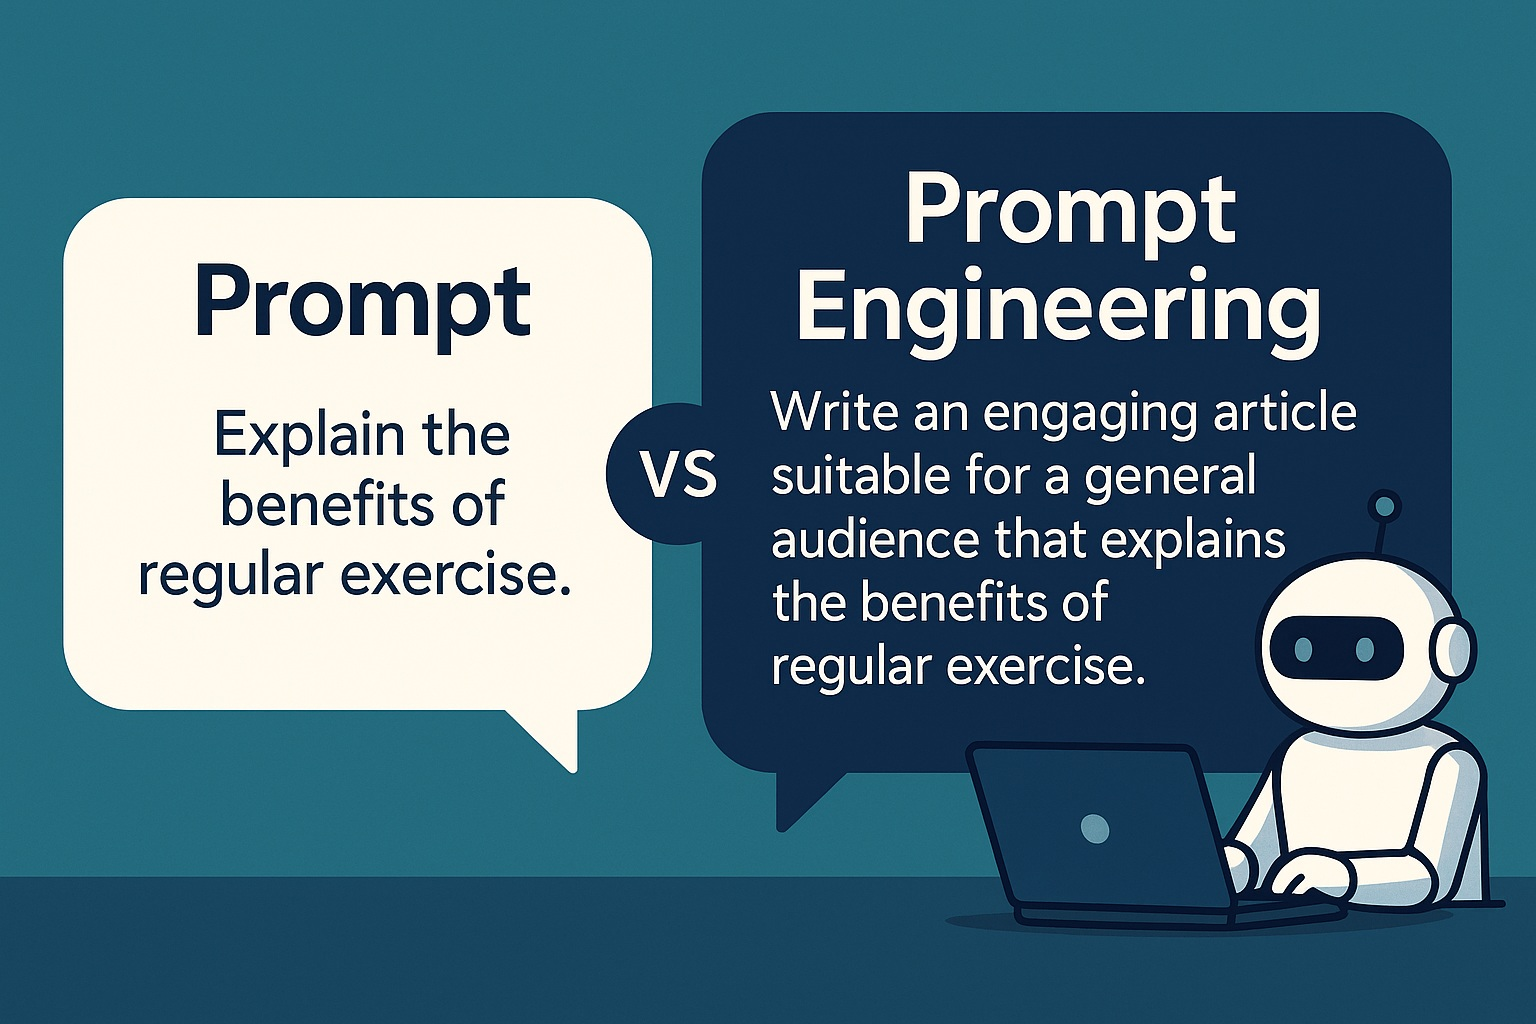

## 1. 프롬프트 엔지니어링이란?
### 1) 개념
- AI가 더 *좋은 답을 내도록 입력, 프롬프트를 설계하는 기술*
- fine -tuning : 모델을 바꿈 <-> 프롬프트 엔지니어링 : 입력만 바꿈

### 2) 프롬프트 vs 파인튜닝, 언제 무엇을 사용?

|구분| 프롬프트 엔지니어링| fine- tuning|
|---|---|---|
|비용|낮음 |높음|
|속도| 바로 시도, 바로 수정 | 학습 시간이 필요|
|성능의 한계| 모델이 가진 능력 내에서만| 모델 자체를 바꿔서 특정 도메인에 맞춤|
|사용 상황| API만 사용할 수 있을 때, 빠른 실험, 요구사항이 자주 변경될 때,| 도메인 특화 데이터가 충분, 일관된 말투나 형식이 계속 필요|

-> 보통 낮은 비용과 바로 수정가능하다는 점 때문에 프롬프트 먼저 시도

## 2. 주요 기법

### 1) zero shot, few shot
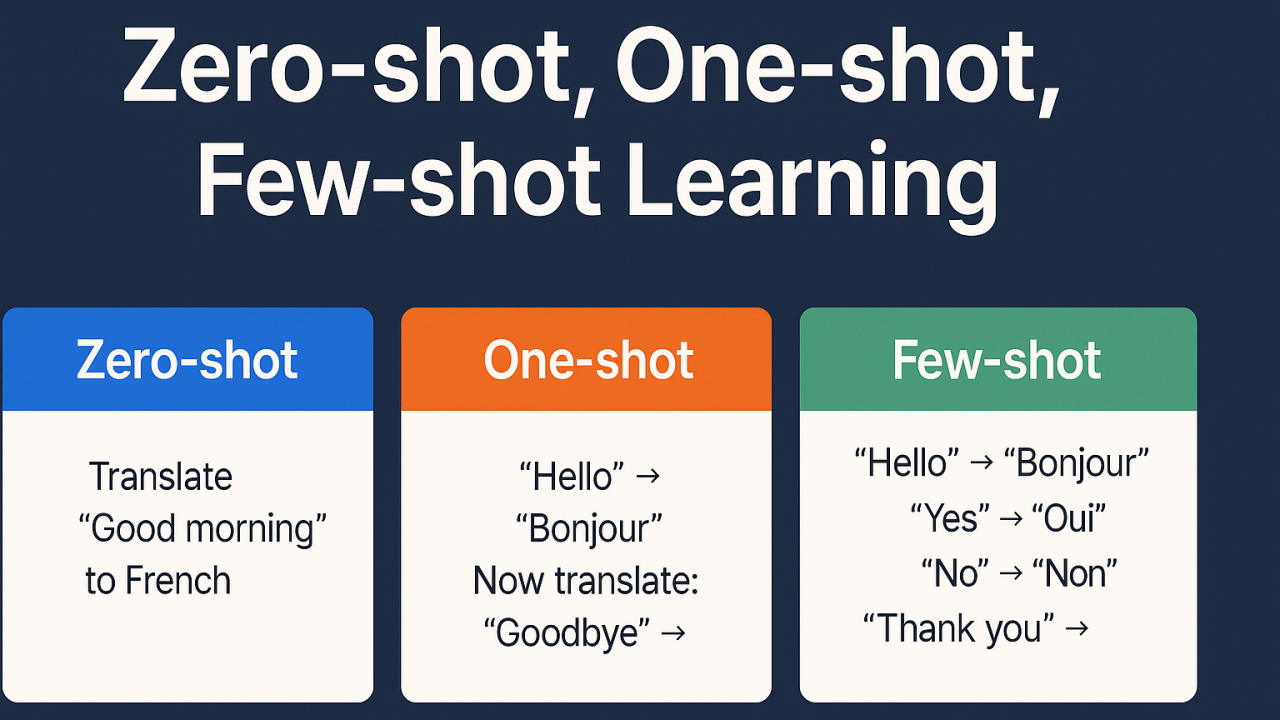<br>
- zero shot : 예시 없이 지시만 주는 방식 <간단하고 명확>
- few shot : 입력, 출력의 예시를 몇 개 보여주고 같은 형식으로 답하게 하는 방식 <출력 형식이나 판단 기준 맞추고 싶을 때>
     - 답의 종류를 (긍,부정 중립) 골고루 하는 것이 중요하다. 어떤 예시냐에 따라 결과가 달라진다.
### 2) Chain of Thought
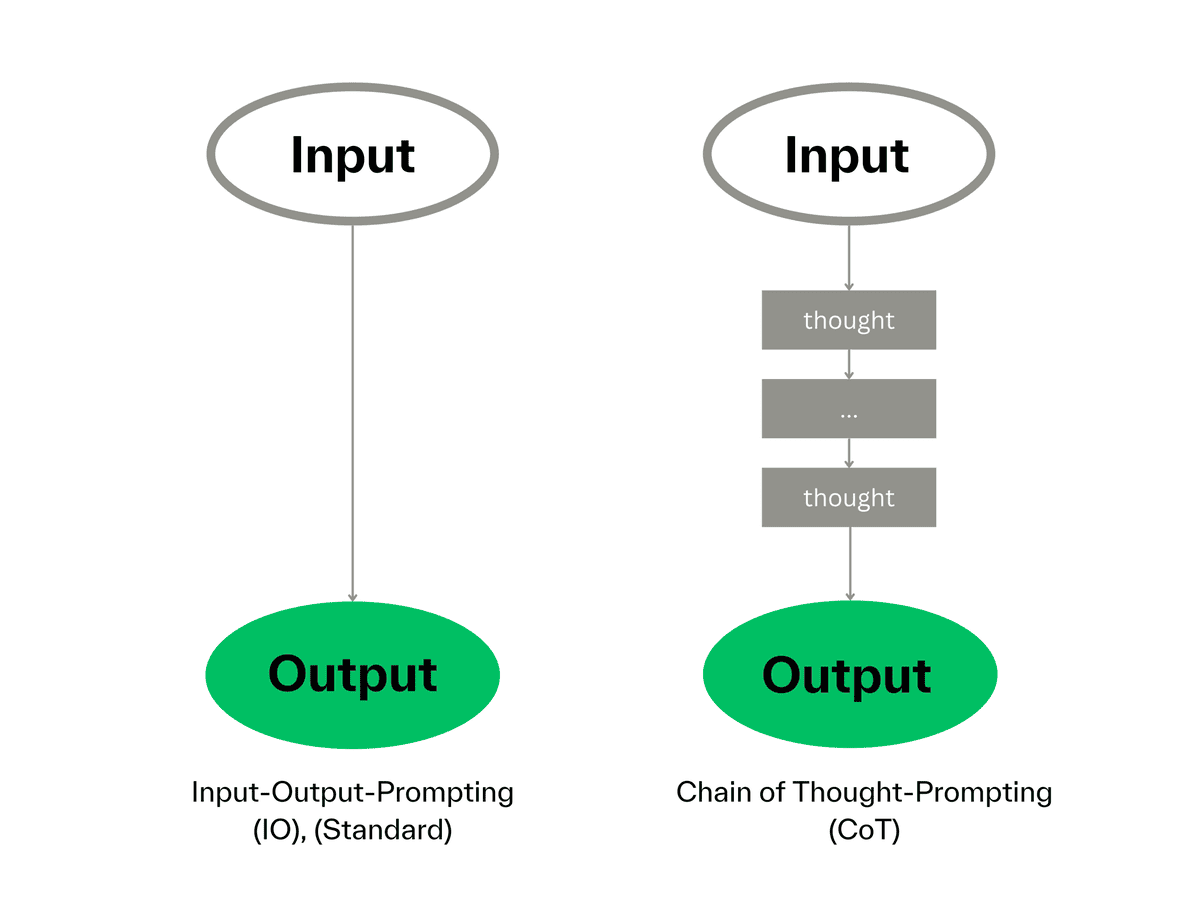 <br>
- 정답만 묻지 말고 중간 풀이 과정을 단계별로 쓰게 하는 방식이다. <계산, 논리, 상식 판단처럼 여러 단계가 필요한 문제>

### 3) role prompting
- 같은 질문도 *누구의 입장인지*에 따라 관점, 강조하는 부분이 달라진다. <말투,관점, 설명 수준 조절>
     - 관점, 말투가 달라질 수 있지만, 모델이 아는 내용이 변화하는 것은 아니다.

### 4) instruction Prompting
- 원하는 것을 *구체적으로* 지시하는 방법. 답의 형식 길이, 누구를 위한 답인지, 필수 내용 등을 정해서 알려준다. <모든 경우의 기본>

### 5) self - consistency
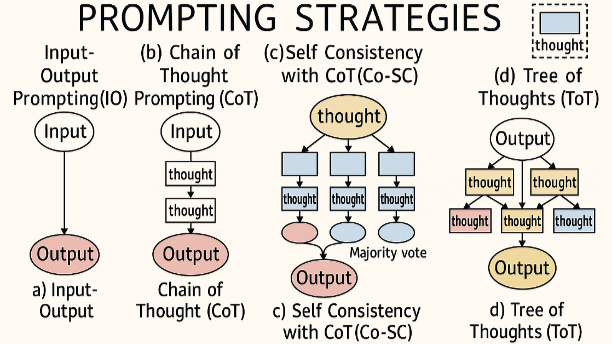 <br>
- 2)을 한 번만 시키면 중간에 틀렸을 때 그대로 믿게 된다. -> 같은 문제를 여러 번 풀게 하고, 가장 많이 나온 최종 답 선택 <정확도가 중요하고 비용 감당이 가능할 때>

## 3. 한계
### 1) prompt injection
- 사용자 입력 자리에 *지시처럼 보이는 문장을 넣어서* 모델이 그 문장을 따르게 만드는 것 (미리 써 둔 지시 말고)
- 왜 발생? 모델은 경계를 확실하게 구분할 수 없음 => 숨겨야 할 지시가 유출될 수도, 숨은 지시를 따를 수도
- 완화 방법 : 지시와 사용자 입력 사이 구분자를 넣기, 모델이 쓸 수 있는 권한 최소화, 출력을 한 번 더 검증

### 2) hallucination
- 사실이 아닌 내용을 그럴듯하게 만들어낸다.
- 완화방법 : 근거가 될 자료를 함께 제공 (RAG), '모르면 모른다고 해줘'라는 지시 넣기, 출처를 요구하고 확인하기

### 3) 모델 의존성
- 같은 프롬프트도 모델이나 버전이 바뀌면 다른 결과가 나온다.
- 완화 방법 : 모델 버전 고정 ('n월 n일 버전'), 회귀 테스트 (자주 쓰는 질문과 기대하는 답을 모아 두고 모델이 바뀔 때마다 다시 돌려본다.)

### 4) 성능 한계
- 모델이 원래 못하는 일은 *프롬프트로도 해결되지 않는다*
- 완화 방법 : 외부 도구를 연결, fine tuning(모델 자체를 해당 작업에 맞게 학습)





# 4. 하네스 엔지니어링
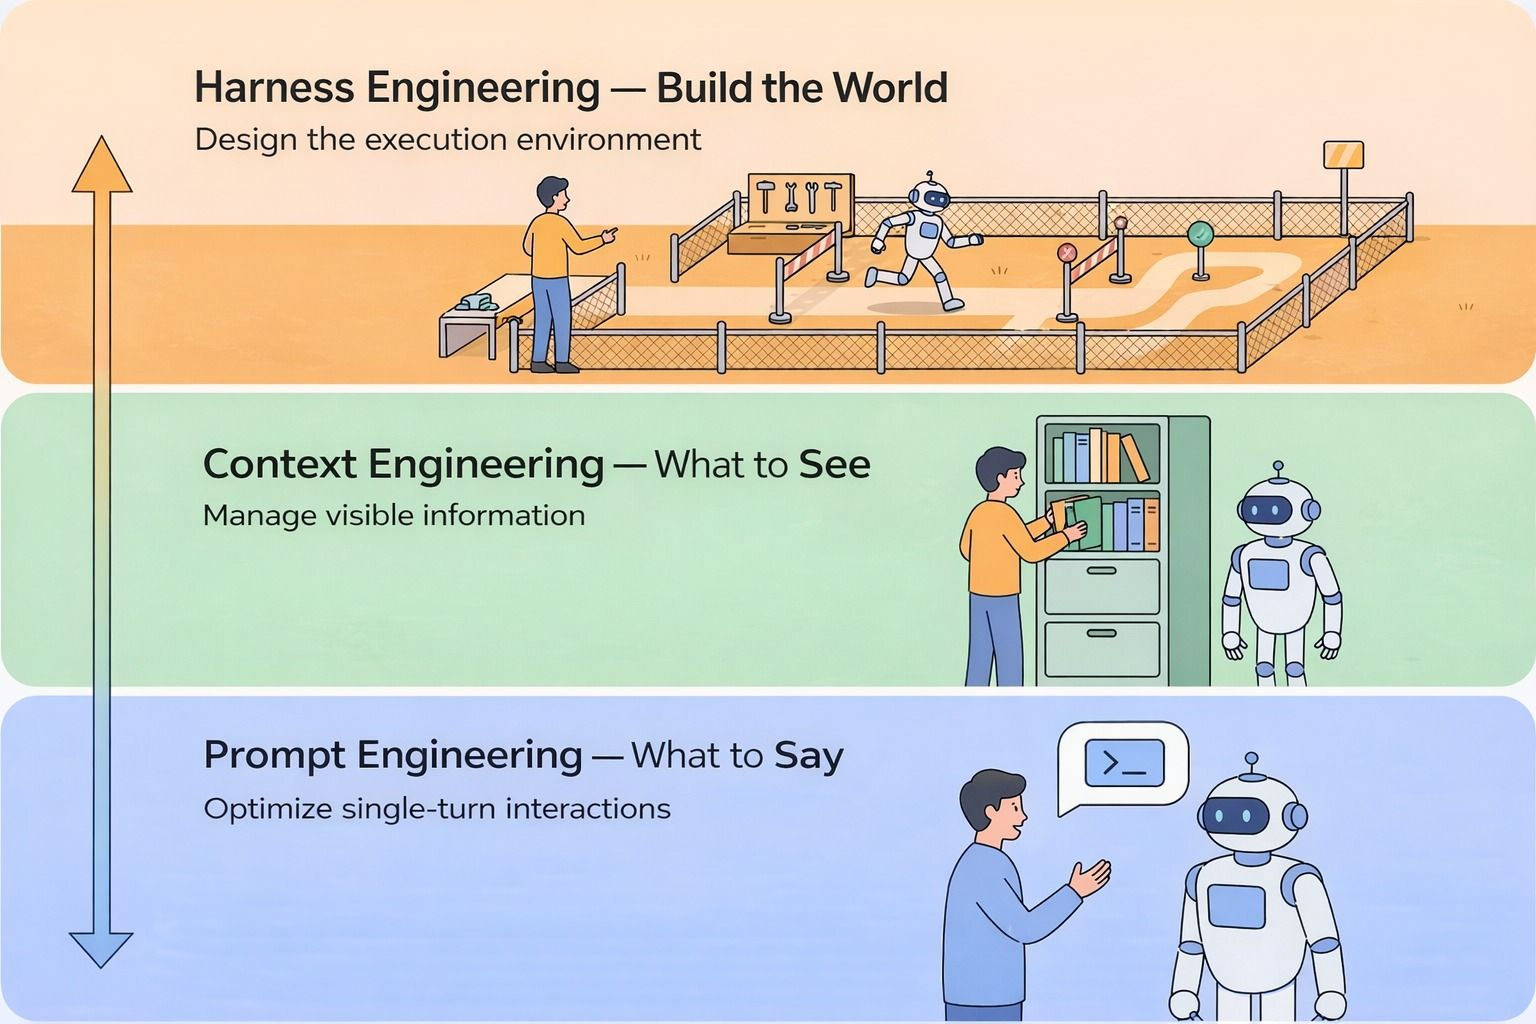

## 1. 프롬프트 다음의 질문

### 1) 프롬프트만으로 안 되는 일
- 실제로는 DB에서 조회하고, 확인하고 다시 시도하는 과정이 필요할 수 있다. 모델이 DB에 접근할 도구가 없다면 프롬프트를 아무리 잘 써도 조회를 할 수 없다/

### 2) 하네스란?
- agent : 도구를 쓰며 여러 단계를 스스로 진행하는 AI (고객센터 AI처럼)
- 1. 모델 본체 : 지금까지 배운 LLM
- 2. 모델이 일하도록 둘러싼 시스템 = **하네스**
- **하네스** : 지시, 컨텍스트, 도구 인터페이스, 실행 환경, 상태, 메모리, 관측, 피드백, 권한, 가드레일 등등
     - 모르는 정보 가져와야할 때
     - 실제로 무언가 실행해야 할 때
     - 결과 확인하고 다시 시도해야 할 때
     - 위험한 행동 막아야 할 때

## 2. 하네스의 구성요소

### 1) 하네스를 이루는 6가지 요소

| 요소 | 무엇을 정하나 | 고객센터 에이전트 예시 |
|---|---|---|
| 지시 컨텍스트 | 모델이 '무엇을 보고 시작?' | 시스템 프롬프트, 고객 정보, 이전 대화|
|도구 인터페이스 | 모델이 '무엇을 어떤 형식으로?' | 주문 조회 도구의 정의|
|실행 환경 | 행동이 실제로 어디서 실행? | 주문 DB에 접근하는 서버, 격리된 실행 공간|
|상태 / 메모리| 지금까지 한 일 어떻게 기억? | 이미 조회한 결과, 진행 단계|
| 관측/ 피드백| 행동의 결과를 어떻게 돌려받나| 도구 반환값, 오류 메세지|
|권한 / 가드레일 | 하면 안되는 것| 조회만 허용, 환불은 사람 승인 후|

### 2) 도구 스키마
- 모델에게 주문 조회 기능을 주려면 *도구 사용 설명서* 필요 -> 모델은 설명서만 읽고 언제 쓸지,, 무엇을 넣을지,,, 결정 => **설명서 = 도구 스키마**

### 3) 성공과 실패의 반환 계약
- 주문 조회했는데 아무것도 안 돌아옴
     - 1) 주문이 정말 없다
     - 2) DB가 응답하지 않는다 (조회 실패)
- 도구가 결과를 *어떤 형태로 돌려줄지 미리 정한다.* = **반환 계약**

## 3. 실패는 어디서 오는가?
### 1) 인터페이스만 달라져도 결과는 달라진다.
- 에이전트의 실패의 이유는 추론력만이 아니다. *인터페이스*(어떤 행동을 어떤 형식으로 할 수 있는가를 정한)에 따라서도 성능과 행동이 달라질 수 있다.

### 2) 증상, 수정할 곳
- 증상 = 하네스 어디를 고칠 것인가?
     - 엉뚱한 도구를 부른다 -> 도구 이름, 설명, 입력 형식
     - 같은 실수 반복한다. -> 도구 반환값, 오류 메세지
     - 앞부분을 잊는다 -> 요약, 진행기록, 모델에게 넘기는 정보
     - 위험한 행동을 바로 실행 -> 허용 범위, 승인, 샌드박스
     - 결과가 맞는지 모른다. -> 테스트, 검증, 완료 조건


# 5. 루프 엔지니어링
## 1 루프 엔지니어링이란?

### 1) 사람이 하던 반복 -> 시스템
- 우리가 하던 일 : 답 읽고, 틀린 곳 찾고, 다시 고쳐달라고 부탁 => 이 시스템을 하도록 만든 것이 루프이다.
- **루프 엔지니어링** ; 모델이 행동 제안, 시스템이 행동 실행, 그 결과를 다시 모델에게 주는 과정을 종료 조건 전까지 반복하도록 설계

- 루프 한 바퀴
     - 1. 관측 : 지금 상황을 봄
     - 2. 판단 : 다음 행동을 정함
     - 3. 행동 : 도구 실행
     - 4. 검증 : 결과가 목표에 맞는지 확인 -> 다음 바퀴의 관측

### 2) 공간에서 시간으로
- 하네스 : 모델이 일하는 공간과 조건 설계
- **루프**: 시간에 따라 어떤 순서로 반복되는지 설계, 결과 보고 다음 행동 정하는 시스템 설계

### 3) 루프의 뿌리 ㅣ ReAct
- ReAct 이전에는 생각만 하는 방식 / 행동만 하는 방식 따로 연구 -> 이를 번갈하 하면서 문제 해결
- thought : 추론, 지금 무엇이 필요한가
- Action : 행동, 검색 도구 호출과 같은 행동 실행
- Observation : 행동의 결과를 보고 다음 생각에 반영

## 2. 루프의 구성 요소

### 1) 루프를 이루는 6가지 구성요소

| 구성요소 | 무엇을 정하나 | 예시 |
|---|---|---|
| 목표 | 무엇을 끝내려 하나 | 레거시 API 쓰는 파일 -> 전부 새 API로 |
|트리거| 언제 루프가 시작?| 사람이 요청 시, 매일 정해진 시간, 코드가 올라오면|
| 관측, 행동 | 매 반복에서 무엇을 보고 무엇을 하나| 파일 검색, 코드 수정, 테스트 실행|
| 정상 종료 조건 | 성공해서 멈춤 | 레거시 API 사용 0건, 전체 테스트 통과 |
| 안전 상한 | 위험해서 멈추는 조건 | 반복 200회, 60분, 20달러|
| 실패 / 승인 처리 | 막혔을 때 / 위험할 때 | 재시도 후 멈추고 보고하기, 삭제 |

- 멈춤 조건 : 성공(정상종료) 또는 위험해서 (안전상한, 실패승인 처리)

### 2) 루프 패턴과 사용 상황
- 재시도 -> 일시적 오류, 성공하면 종료
- 주기 실행 -> 매일 아침 리포트 생성, 해당 회차 작업 완료
- 이벤트 트리거 -> 코드 올라오면 자동적으로 리뷰, 리뷰 작성 완료
- 목표 달성까지 반복 -> 레거시 API 마이그레이션
- 어떤 패턴이든 종료 조건 & 안전 상한을 같이 적는다. 

## 3. 통제

### 1) 루프에서 증폭되는 실패
- 작은 실수도 루프에서 반복되면 자동으로 실행되면서 영향력이 커진다.
- 무한 반복, 토큰/비용 폭주, 컨텍스트 누적-> 품질 저하, 같은 부작용의 반복, 되돌리기 어려운 행동

### 2) 통제 장치
- 실패마다 막는 장치가 있다
- 예시 :
     -  반복/시간/비용 상한=> 무한 반복과 비용 폭주를 막음
     -  테스트와 완료 조건 => 끝나지 않았는데 끝났다고 하는 문제 막음
     - 중복 실행 방지 => 같은 부작용 반복을 막음
     - 체크포인트와 롤백 => 중간에 잘못된 변경이 쌓이는 것.
     - 위험도에 따른 행동을 분리 => 되돌리기 어려운 행동 자동 실행
          - 자동실행/사후검토/사람 승인 후 실행으로 나눔

### 3) 학습 단계의 정렬, 실행 단계의 통제
- RLHF (사람의 선호와 기준에 가깝게) -> 모델 안을 바꾸는 방법 : **학습 단계의 정렬**
- 위험한 행동은 사람이 승인을 해야지만 실행, 권한은 최소화, 결과는 테스트로 검증 :**실행 단계의 통제**

# 6. 정리
## 상황 -> 무엇을 손볼까

| 상황 | 무엇을 손볼까 | 무엇이 바뀌나|
|---|---|---|
| 도메인 특화 성능 필요, 데이터 충분 | fine tuning, peft | 모델 파라미터|
|모바일에 올려야 함| 경량화|모델 크기와 연산량|
|사람이 원하는 답이 안나옴| 정렬 RLHF | 모델의 행동 기준|
|API만 쓸 수 있고, 출력 형식이 문제 | 프롬프트 | 모델에 넣는 입력|
| 도구를 쓰거나 파일을 읽어야 함| 하네스 | 모델이 일하는 환경|
| 사람이 매번 시키는 것이 문제 | 루프 | 반복, 멈추는 조건|